---

### FSW3D - short demo

---

In [1]:
# access fsw3d library by adding project root to sys.path
import sys, os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### other
import mrcfile

### fsw3d
from fast_volume_align_ot import plots, transforms, signals, alignments

---

### 1) compute alignment from voxelized data

---

In [1]:
### Example computing alignment for two cryo-EM volumes

volume_1_file = 'path/to/mrcfile1/0.mrc'
volume_2_file = 'path/to/mrcfile2/49.mrc'

with mrcfile.open(volume_1_file, permissive=True) as mrc:
    f = mrc.data
    mrc.close()

with mrcfile.open(volume_2_file, permissive=True) as mrc:
    g = mrc.data
    mrc.close()

### Normalize the data and compute input grid
N = f.shape[0]  ### assumes equal dimension
grid = transforms.Grids(N=N)
f = signals.Signal(f, d=3).preprocess_signals()[0]
g = signals.Signal(g, d=3).preprocess_signals()[0]

### Compute alignment in Euclidean distance
t = time.time()
alignment_l2 = (alignments.Alignment(f, g, grid, metric='L2'))
print("alignment L2   = ", time.time() - t)
print('\n')

### Compute alignment in ramp-filtered sliced 2-Wasserstein distance
t = time.time()
alignment_rfsw = (alignments.Alignment(f, g, grid, metric='RFSW'))
print("alignment RFSW = ", time.time() - t)
print('\n')

Euclidean distance alignment


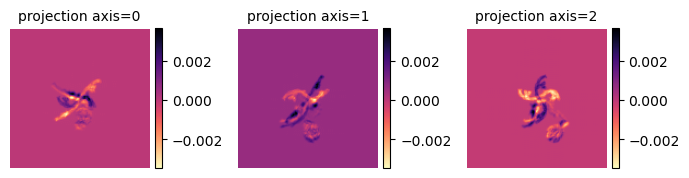

ramp-filtered sliced 2-Wasserstein distance alignment


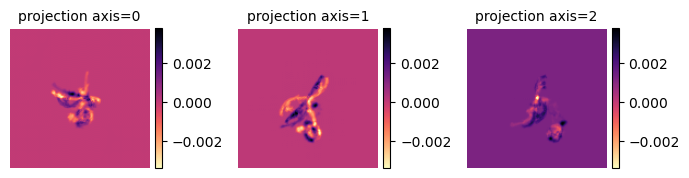

In [3]:
print('Euclidean distance alignment')
plots.orthogonal_2D_projection_plot(f - alignment_l2.aligned, cmap='magma_r')

print('ramp-filtered sliced 2-Wasserstein distance alignment')
plots.orthogonal_2D_projection_plot(f - alignment_rfsw.aligned, cmap='magma_r')

### save as mrc file
# with mrcfile.new('Output/aligned_l2.mrc', overwrite=True) as mrc:
#     mrc.set_data(alignment_l2.aligned.astype('float32'))

# with mrcfile.new('Output/aligned_rfsw.mrc', overwrite=True) as mrc:
#     mrc.set_data(alignment_rfsw.aligned.astype('float32'))

In [4]:
### compare the alignment matrix
print('Euclidean alignment matrix')
print(alignment_l2.R)
print('\n')
print('RFSW alignment matrix')
print(alignment_rfsw.R)

Euclidean alignment matrix
[[ 0.29369037  0.9425064  -0.15946052]
 [-0.88792337  0.33076553  0.31966584]
 [ 0.35403115  0.04770594  0.93401611]]


RFSW alignment matrix
[[ 0.59781973  0.48585762 -0.63761583]
 [-0.80065201  0.32259898 -0.50486261]
 [-0.03959713  0.81232522  0.58185892]]


---

### 2) compute transforms of voxelized data

---

In [1]:
### You can also compute and access the transformed data too

d = 3  # for 3-D data

volume_1_file = 'path/to/mrcfile1/0.mrc'
volume_2_file = 'path/to/mrcfile2/49.mrc'

with mrcfile.open(volume_1_file, permissive=True) as mrc:
    f = mrc.data
    mrc.close()

with mrcfile.open(volume_2_file, permissive=True) as mrc:
    g = mrc.data
    mrc.close()

### Normalize the data and compute input grid
N = f.shape[0]  ### assumes equal dimension
grid = transforms.Grids(N=N)
f = signals.Signal(f, d=3).preprocess_signals()[0]
g = signals.Signal(g, d=3).preprocess_signals()[0]

In [6]:
### Compute transforms

### Radon transform
t = time.time()
f_rt = transforms.Transform(f, d, grid).radon_transform()[0]
print('Radon transform {}^3 = '.format(N), time.time() - t)

### Quantile tensor / ICDF transform
t = time.time()
f_t = transforms.Transform(f, d, grid).inverse_cdf_transform()[0]
print('ICDF transform {}^3 = '.format(N), time.time() - t) 

### ramp-filtered version
f_tp, f_tn = transforms.Transform(f, d=3, grid=grid, apply_ramp=True).signed_inverse_cdf_transform()
f_tp, f_tn = f_tp[0], f_tn[0]
print('ramp-filtered ICDF transform {}^3 = '.format(N), time.time() - t)

Radon transform 128^3 =  0.3042752742767334
ICDF transform 128^3 =  0.4342339038848877
ramp-filtered ICDF transform 128^3 =  0.9946739673614502


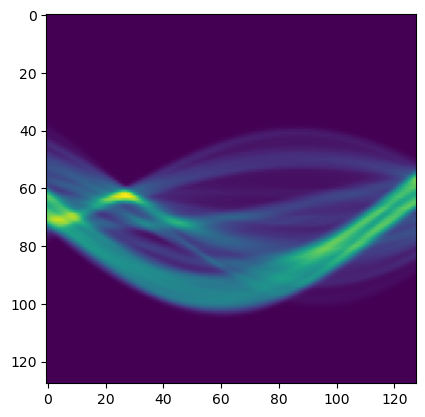

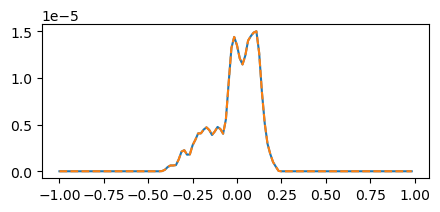

In [7]:
plt.imshow(f_rt[0, :, :])
plt.show()
plt.figure(figsize=(5,2))
plt.plot(grid.zs, np.sum(f, axis=(0,1)) * (grid.zs[1] - grid.zs[0]) ** 2)
plt.plot(grid.zs, f_rt[0, :, 0], '--')
plt.show()

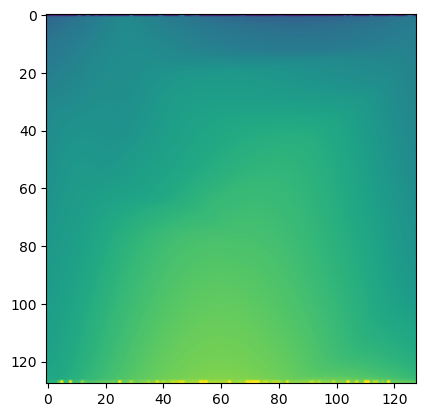

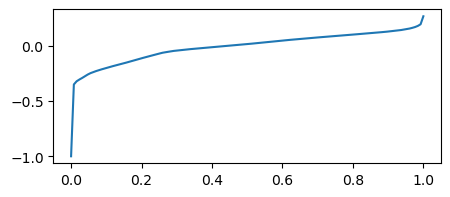

In [8]:
plt.imshow(f_t[0, :, :])
plt.show()
plt.figure(figsize=(5,2))
plt.plot(grid.ts, f_t[0, :, 0])
plt.show()

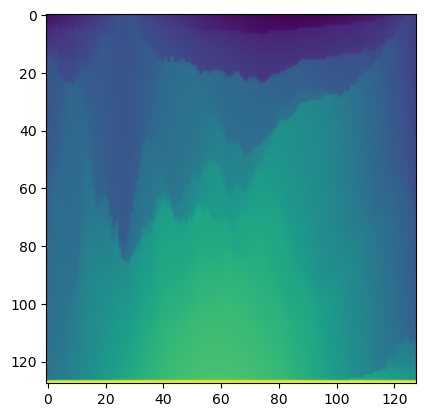

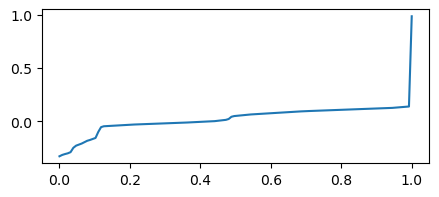

In [9]:
plt.imshow(f_tp[0, :, :])
plt.show()
plt.figure(figsize=(5,2))
plt.plot(grid.ts, f_tp[0, :, 0])
plt.show()